# Финальный экзамен: плей-офф НХЛ 2025/2026

**Слуцкая** **Изабелла** **MAF**

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

sns.set_context('notebook')
pd.set_option('float_format', '{:6.3f}'.format)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 200)

## Задача 1. Чтение данных


In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events['Date'] = pd.to_datetime(events['Date'])

print(events.shape)
print(events.iloc[:10, [2, 3, 4, 9, 12]])

(29710, 38)
        Date      Away Team       Home Team Remaining Time     Play Type
0 2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1 2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2 2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3 2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4 2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5 2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6 2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7 2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8 2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9 2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot


Размер таблицы (29710, 38).

## Задача 2. Сводная таблица по играм


In [3]:
last = events.groupby('Game ID').last()

games = last[['Date', 'Away Team', 'Home Team', 'Cumulated Away Score', 'Cumulated Home Score', 'Period']].copy()
games.columns = ['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Period']


def outcome(period):
    if period == 3:
        return 'Final'
    elif period == 4:
        return 'Final/OT'
    else:
        return f'Final/{period - 3}OT'


games['Outcome'] = games['Period'].map(outcome)
games = games.drop(columns='Period')

print(games.columns)
print(games.iloc[-5:, -4:])
print(games['Outcome'].value_counts())

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='object')
                       Home Team  Away Score  Home Score    Outcome
Game ID                                                            
2025030412   Carolina Hurricanes           3           4   Final/OT
2025030413  Vegas Golden Knights           4           5  Final/2OT
2025030414  Vegas Golden Knights           5           3      Final
2025030415   Carolina Hurricanes           2           4      Final
2025030416  Vegas Golden Knights           3           0      Final
Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64


Всего 82 игры: 60 закончились в основное время, 18 в одном овертайме и 4 в двух.

## Задача 3. Функция gameInfo


In [4]:
def gameInfo(gameId):
    g = games.loc[gameId]
    date = g['Date'].strftime('%Y-%m-%d')
    return f"{g['Home Team']} - {g['Away Team']} ({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {date})"


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## Задача 4. Число голов за игру

In [5]:
games['Total Score'] = games['Away Score'] + games['Home Score']
print(games['Total Score'].describe())

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64


Всего забито 486 шайб, в среднем 5.93 за игру. Медиана равна 6, то есть половина матчей закончилась с 6 голами или меньше. Разброс небольшой: у средних 50% игр от 5 до 7 голов, а максимум 15.

## Задача 5. Гистограмма числа голов

По горизонтали все значения от 1 до 15, чтобы пустые значения (12, 13, 14) тоже были видны.

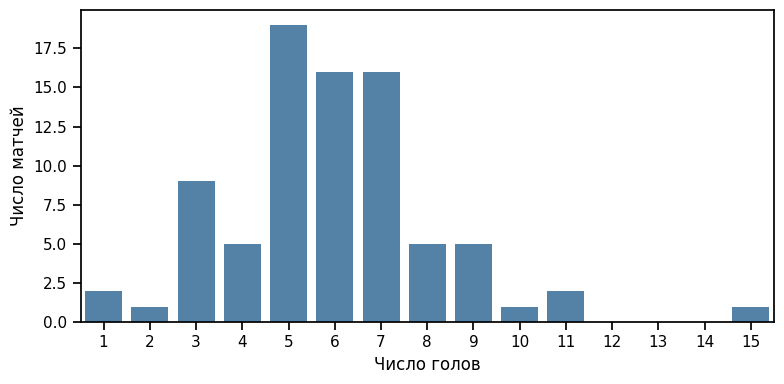

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64


In [6]:
plt.figure(figsize=(8, 4))
sns.countplot(x='Total Score', data=games, order=range(1, games['Total Score'].max() + 1), color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.tight_layout()
plt.savefig('fig5_goals_per_game.png', dpi=150)
plt.show()

print(games['Total Score'].value_counts().sort_index())

**Комментарий.** Больше всего матчей с 5 голами (19 игр), дальше идут 6 и 7 голов (по 16 игр). Эти три значения вместе дают 51 игру из 82. Картина в целом симметричная с центром около 6, но справа есть длинный хвост: одиннадцать и больше голов было в трёх играх, а одна игра дала целых 15. Слева хвоста почти нет, потому что меньше одного гола в игре, где кто-то выиграл, быть не может. Игр с 1–2 голами всего три.

## Задача 6. Самые нерезультативные и самые результативные игры

In [7]:
low = games[games['Total Score'] == games['Total Score'].min()]
high = games[games['Total Score'] == games['Total Score'].max()]

print([gameInfo(i) for i in low.index])
print([gameInfo(i) for i in high.index])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Самых нерезультативных игр две, обе закончились 1:0 в овертайме. Самая результативная одна: 9:6 в игре Колорадо и Миннесоты (15 голов).

## Задача 7. Сколько игроков участвовало в каждой игре

Собираем в одну длинную таблицу все 14 столбцов с игроками на льду (по 6 полевых и вратарь у каждой команды), убираем пустые значения и повторы внутри одной игры. Потом считаем, сколько разных фамилий осталось в каждой игре.

In [8]:
away_cols = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Away Team's Goalie"]
home_cols = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Home Team's Goalie"]
ice_cols = away_cols + home_cols

players_in_game = events.melt(id_vars='Game ID', value_vars=ice_cols, value_name='Player')
players_in_game = players_in_game.dropna(subset=['Player']).drop_duplicates(['Game ID', 'Player'])

player_count = players_in_game.groupby('Game ID').size()
counts = pd.DataFrame({'Game Info': [gameInfo(i) for i in player_count.index],
                       'Player Count': player_count})

print(counts[counts['Player Count'] == counts['Player Count'].max()])
print(counts['Player Count'].describe())

                                                                 Game Info  Player Count
Game ID                                                                                 
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)            40
count   82.000
mean    38.122
std      0.365
min     38.000
25%     38.000
50%     38.000
75%     38.000
max     40.000
Name: Player Count, dtype: float64


**Комментарий.** Игра с наибольшим числом участников одна: Монреаль - Баффало (3:8). В ней вышло 40 игроков. В остальных играх почти всегда ровно 38 (это 2 команды по 19 человек: 18 полевых и вратарь). В игре с 40 игроками обе команды меняли вратаря, отсюда два лишних человека.

## Задача 8. Расстояние до ворот для бросков

Берём события `goal`, `shot-on-goal` и `missed-shot`. Шаги такие:

1. Выясняем, кто бросает: хозяева или гости.
2. По полю `Home Team's Defending Side` понимаем, в какие ворота бьёт эта команда: хозяева бьют вправо (X = 89), если сами защищают левую сторону, и влево, если правую. У гостей наоборот.
3. Расстояние по горизонтали это модуль разности X броска и X ворот. По вертикали расстояние до ворот равно нулю, пока бросок в пределах створа (от -3 до 3), а дальше это модуль Y минус 3. Это то же самое, что три случая в формуле из условия, только записано короче.
4. Складываем по теореме Пифагора.

In [9]:
shot_types = ['goal', 'shot-on-goal', 'missed-shot']
shots = events[events['Play Type'].isin(shot_types)].copy()

home_shot = shots['Team Making the Play'] == shots['Home Team']
home_defends_left = shots["Home Team's Defending Side"] == 'left'
shoots_right = (home_shot & home_defends_left) | (~home_shot & ~home_defends_left)
goal_x = np.where(shoots_right, 89, -89)

dx = (shots['X Coordinate on the Ice Rink'] - goal_x).abs()
dy = np.maximum(shots['Y Coordinate on the Ice Rink'].abs() - 3, 0)
shots['Shot Length'] = np.sqrt(dx ** 2 + dy ** 2)

events['Shot Length'] = shots['Shot Length']
print(events[events['Play Type'].isin(shot_types)][['Game ID', 'Play Type', 'Shot Length']])

          Game ID     Play Type  Shot Length
7      2025030111   missed-shot       12.207
9      2025030111   missed-shot       12.000
12     2025030111   missed-shot       29.411
13     2025030111  shot-on-goal       62.169
19     2025030111   missed-shot       52.924
...           ...           ...          ...
29695  2025030416   missed-shot       54.083
29696  2025030416   missed-shot        5.099
29704  2025030416          goal       46.239
29706  2025030416   missed-shot       60.926
29707  2025030416  shot-on-goal       49.041

[7266 rows x 3 columns]


Получилось 7266 бросков.

## Задача 9. Длина точных и неточных бросков

К точным относим `goal` и `shot-on-goal` (4623 броска), к неточным `missed-shot` (2643 броска). Групп разного размера, поэтому на гистограмме по вертикали стоит плотность, и каждая группа нормируется отдельно (`common_norm=False`). Иначе точные броски просто выглядели бы выше только потому, что их больше.

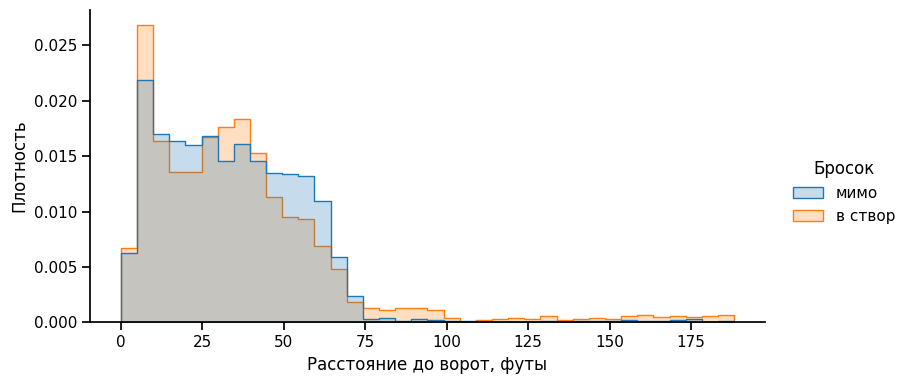

           count   mean    std    min    25%    50%    75%     max
Бросок                                                            
в створ 4623.000 36.207 29.997  0.000 15.000 31.828 47.011 188.215
мимо    2643.000 34.014 22.313  0.000 16.155 32.249 49.041 185.068


In [10]:
shots['Бросок'] = np.where(shots['Play Type'] == 'missed-shot', 'мимо', 'в створ')

g = sns.displot(data=shots, x='Shot Length', hue='Бросок', stat='density', common_norm=False,
                binwidth=5, element='step', height=4, aspect=2)
g.set_axis_labels('Расстояние до ворот, футы', 'Плотность')
plt.savefig('fig9_shot_length.png', dpi=150)
plt.show()

print(shots.groupby('Бросок')['Shot Length'].describe())

**Комментарий.** Основная масса бросков у обеих групп похожа: пик на 5–10 футах (броски почти от самых ворот), потом плавный спад к 70 футам. Медиана почти одинаковая (около 32 футов). Отличия такие:

- С 45 до 70 футов неточных бросков заметно больше: они составляют 28% всех неточных против 20% у точных. С дальних позиций мазать проще.
- Дальше 70 футов картина обратная: там точных бросков 7.2% от всех точных и только 2.4% от неточных. Дальше 100 футов (то есть уже с чужой половины) это 3.5% против 0.9%.

In [11]:
long_goals = shots[(shots['Play Type'] == 'goal') & (shots['Shot Length'] > 100)].copy()
scorer_is_home = long_goals['Team Making the Play'] == long_goals['Home Team']
long_goals['Lead After Goal'] = np.where(scorer_is_home,
                                         long_goals['Cumulated Home Score'] - long_goals['Cumulated Away Score'],
                                         long_goals['Cumulated Away Score'] - long_goals['Cumulated Home Score'])

print(len(long_goals), 'голов с расстояния больше 100 футов из', (shots['Play Type'] == 'goal').sum())
print(long_goals[['Game ID', 'Period', 'Remaining Time', 'Team Making the Play', 'Lead After Goal']])

far = shots[shots['Shot Length'] > 100]
print(far['Play Type'].value_counts())

17 голов с расстояния больше 100 футов из 486
          Game ID  Period Remaining Time  Team Making the Play  Lead After Goal
10308  2025030161       3          03:08        Minnesota Wild                5
10669  2025030162       3          00:50          Dallas Stars                2
12162  2025030166       3          00:15        Minnesota Wild                3
12532  2025030171       3          01:39  Vegas Golden Knights                2
14565  2025030176       3          03:36  Vegas Golden Knights                4
15320  2025030182       3          01:10         Anaheim Ducks                2
15676  2025030183       3          01:33         Anaheim Ducks                3
18662  2025030216       3          05:48        Buffalo Sabres                4
20945  2025030231       3          02:08    Colorado Avalanche                3
21289  2025030232       3          00:05    Colorado Avalanche                3
21639  2025030233       3          00:04        Minnesota Wild            

**Почему длинный хвост у точных бросков.** Всего дальше 100 футов бросков по воротам 160, и это два разных случая.

1. **17 голов.** Все они забиты в третьем периоде, причём за последние 6 минут (самый ранний гол за 5:48 до конца), и каждый раз команда после гола вела минимум на 2 шайбы. Это похоже на голы в пустые ворота: проигрывающая команда в конце снимает вратаря, а лидер добивает шайбой через всю площадку. В трёх таких эпизодах вратаря в данных нет совсем (пустое значение), в остальных он по записи остаётся, так что прямого подтверждения в таблице нет.
2. **143 броска, которые взял вратарь.** Они разбросаны по всем периодам (52 в первом, 48 во втором, 34 в третьем), так что к концу игры это не привязано. Похоже на дальние броски и выбросы шайбы в сторону чужих ворот, которые вратарь ловит: такая шайба записывается как бросок в створ. Если же она пролетела мимо, её, скорее всего, вообще не записывают как бросок, это просто выброс шайбы.

## Задача 10. Доля точных бросков среди незаблокированных

Незаблокированные броски это `goal`, `shot-on-goal` и `missed-shot`. Для каждой команды в каждой игре считаем, сколько их каждого типа, и берём долю (голы + броски в створ) / все незаблокированные броски.

In [12]:
counts_by_type = pd.crosstab([shots['Game ID'], shots['Team Making the Play']], shots['Play Type'])

numshots = pd.DataFrame()
numshots['Shot'] = counts_by_type['goal'] + counts_by_type['shot-on-goal']
numshots['Goal'] = counts_by_type['goal']
numshots['Share of Shots on Goal'] = numshots['Shot'] / (numshots['Shot'] + counts_by_type['missed-shot'])

print(numshots['Share of Shots on Goal'])
print(numshots['Share of Shots on Goal'].describe())
print('Незаблокированных бросков за игру у одной команды в среднем:', counts_by_type.sum(axis=1).mean())

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64
count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64
Незаблокированных бросков за игру у одной команды в среднем: 44.30487804878049


**Комментарий.** Всего 164 пары «команда - игра», как в примере. В среднем около 64% незаблокированных бросков (и среднее, и медиана 0.639) попадают в створ. Остальные 36% летят мимо. Разброс между играми заметный: от 0.353 до 0.860.

## Задача 11. Команды с самой высокой и самой низкой долей точных бросков

In [13]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()

print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

top_and_bottom = list(avgnumshots.nlargest(5).index) + list(avgnumshots.nsmallest(5).index)
print(numshots.groupby('Team Making the Play').size()[top_and_bottom])

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Edmonton Oilers         6
Philadelphia Flyers    10
Dallas Stars            6
Minnesota Wild         11
Colorado Avalanche     13
Pittsburgh Penguins     6
Utah Mammoth            6
Carolina Hurricanes    19
Tampa Bay Lightning     7
Buffalo Sabres         13
dtype: int64


**Комментарий.** Выше всего доля точных бросков у Эдмонтона (0.706), Филадельфии (0.684) и Далласа (0.670). Ниже всего у Питтсбурга (0.554) и Юты (0.599). Разница между первым и последним местом около 0.15, это заметно.

Но надо учесть, что команды сыграли разное число игр: Эдмонтон, Даллас, Питтсбург и Юта по 6, а Каролина 19.

## Задача 12. Средние броски в створ и голы за игру

In [14]:
avgshots = numshots[['Shot', 'Goal']].groupby('Team Making the Play').mean()
print(avgshots)

                       Shot   Goal
Team Making the Play              
Anaheim Ducks        31.667  3.250
Boston Bruins        25.167  2.000
Buffalo Sabres       30.462  3.308
Carolina Hurricanes  31.632  3.474
Colorado Avalanche   32.154  3.385
Dallas Stars         31.000  2.500
Edmonton Oilers      28.333  3.500
Los Angeles Kings    25.250  1.250
Minnesota Wild       28.727  3.727
Montréal Canadiens   23.263  2.842
Ottawa Senators      27.500  1.250
Philadelphia Flyers  24.600  2.100
Pittsburgh Penguins  26.500  1.833
Tampa Bay Lightning  28.000  2.143
Utah Mammoth         27.833  3.000
Vegas Golden Knights 26.545  3.455


Броски в створ здесь это `shot-on-goal` вместе с `goal`, потому что гол тоже бросок, который попал в створ. Средние считаются по всем играм команды, включая те, где она не забила.

## Задача 13. Связь бросков в створ и голов

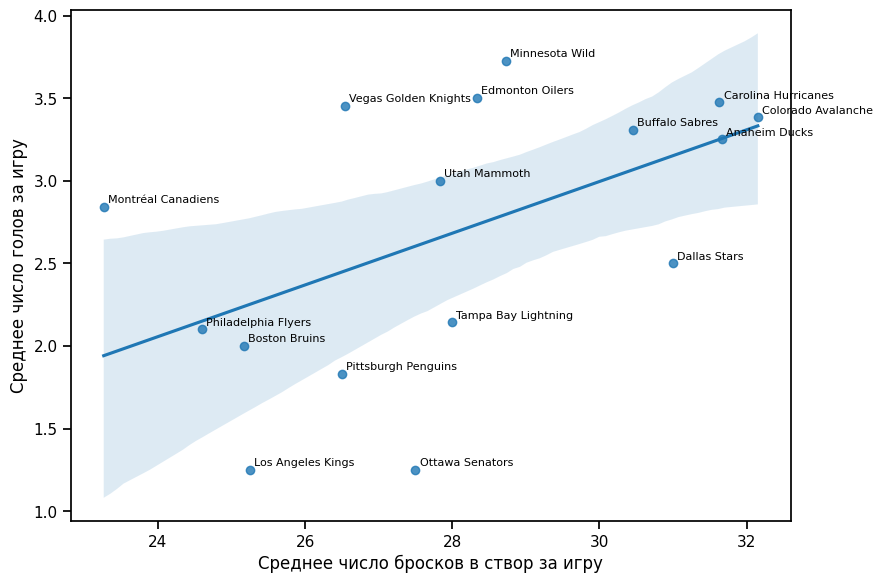

       Shot   Goal
Shot  1.000  0.521
Goal  0.521  1.000


In [15]:
plt.figure(figsize=(9, 6))
sns.regplot(x='Shot', y='Goal', data=avgshots)
for team, row in avgshots.iterrows():
    plt.annotate(team, (row['Shot'], row['Goal']), fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.tight_layout()
plt.savefig('fig13_shots_goals.png', dpi=150)
plt.show()

print(avgshots.corr())

**Комментарий.** Связь есть, но слабая. Линия идёт вверх: команды, которые больше бросают в створ, в среднем и забивают больше. Коэффициент корреляции 0.52, то есть умеренная положительная связь, и точек всего 16, поэтому доверительная полоса вокруг линии широкая.

Выбросов много. Вегас (26.5 броска и 3.45 гола) и Монреаль (23.3 и 2.84) забивают заметно больше, чем «положено» по линии. Даллас (31.0 и 2.50), Лос-Анджелес и Оттава (по 1.25 гола) заметно меньше.

## Задача 14. Игра с наибольшим числом ударов по воротам

Считаем все четыре типа: голы, броски в створ, броски мимо и заблокированные броски.

In [16]:
all_shot_types = ['goal', 'shot-on-goal', 'missed-shot', 'blocked-shot']
all_shots = events[events['Play Type'].isin(all_shot_types)].copy()

shots_per_game = all_shots.groupby('Game ID').size()
print(shots_per_game.nlargest(3))

idxmax = shots_per_game.idxmax()
print(gameInfo(idxmax))

Game ID
2025030132    208
2025030164    169
2025030413    163
dtype: int64
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Больше всего ударов (208) было в матче Каролина - Оттава (3:2, два овертайма). Следующая по ударам игра сильно отстаёт (169), так что претендентов на это место нет.

## Задача 15. Где наносились броски в этой игре

По условию координаты разворачиваем в нечётных периодах: (x, y) превращается в (-x, -y). После этого гости всегда бьют в левые ворота, а хозяева в правые.

Team Making the Play
Carolina Hurricanes    61.257
Ottawa Senators       -63.707
Name: Plot X, dtype: float64
Play Type             blocked-shot  goal  missed-shot  shot-on-goal
Team Making the Play                                               
Carolina Hurricanes             26     3           34            46
Ottawa Senators                 28     2           32            37


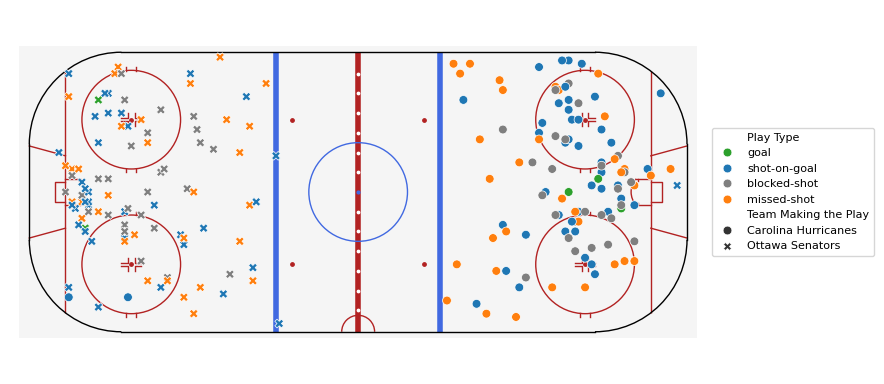

In [17]:
one = all_shots[all_shots['Game ID'] == idxmax].copy()

sign = np.where(one['Period'] % 2 == 1, -1, 1)
one['Plot X'] = sign * one['X Coordinate on the Ice Rink']
one['Plot Y'] = sign * one['Y Coordinate on the Ice Rink']

print(one.groupby('Team Making the Play')['Plot X'].mean())
print(pd.crosstab(one['Team Making the Play'], one['Play Type']))

plt.figure(figsize=(9, 4))
plot_rink()
sns.scatterplot(data=one, x='Plot X', y='Plot Y', hue='Play Type', style='Team Making the Play',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette={'goal': 'tab:green', 'shot-on-goal': 'tab:blue',
                         'blocked-shot': 'tab:gray', 'missed-shot': 'tab:orange'},
                s=40)
plt.axis('equal')
plt.axis('off')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.savefig('fig15_rink_shots.png', dpi=150)
plt.show()

**Комментарий.** Каролина (кружки, хозяева) бьёт вправо, Оттава (крестики, гости) влево, так что у хозяев средний x около +61, а у гостей около -64. Это значит, что координаты развёрнуты правильно.

У ворот Оттавы броски Каролины плотно собраны перед воротами и у кругов вбрасывания, у ворот Каролины картина более рассыпанная. Всего ударов 109 у Каролины (3 гола, 46 в створ, 34 мимо, 26 заблокировано) и 99 у Оттавы (2 гола, 37 в створ, 32 мимо, 28 заблокировано). Зелёных точек на картинке мало, потому что голов всего пять и они лежат поверх других точек. Несколько крестиков и кружков с «чужой» стороны это длинные броски с дальней позиции.

## Задачи 16–18. Лучшие бомбардиры, ассистенты и очки


In [18]:
def top10(series):
    border = series.nlargest(10).min()
    return series[series >= border].sort_values(ascending=False)


goals = events[events['Play Type'] == 'goal']

**16. Больше всего голов.** Автор гола это `Player in the Event #1`.

In [19]:
goals_by_player = goals['Player in the Event #1'].value_counts()
print(top10(goals_by_player))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Jordan Staal         8
Nikolaj Ehlers       8
Nathan MacKinnon     7
Taylor Hall          7
Mark Stone           7
Jackson Blake        7
Alex Newhook         7
Matt Boldy           7
Name: count, dtype: int64


Лидер Brett Howden (14 голов), дальше Pavel Dorofeyev (12), Logan Stankoven (11), Mitch Marner (10). С 7 голами шестеро игроков (места с 7-го по 12-е).

**17. Больше всего голевых передач.** Передачи это `Player in the Event #2` и `#3` у голов.

In [20]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).value_counts()
print(top10(assists))

Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Taylor Hall        12
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Quinn Hughes       11
Kirill Kaprizov    11
Name: count, dtype: int64


Лидер Jack Eichel (20 передач), второй Mitch Marner (19). Дальше с большим отрывом идут Lane Hutson и Jackson Blake (по 13).

**18. Больше всего очков (голы + передачи).**

In [21]:
points = goals_by_player.add(assists, fill_value=0).astype(int)
print(top10(points))

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Nick Suzuki        16
Logan Stankoven    16
Lane Hutson        16
Pavel Dorofeyev    16
Name: count, dtype: int64


Лидер Mitch Marner (29 очков: 10 голов и 19 передач), второй Jack Eichel (22), третий Jackson Blake (20). С 16 очками четыре игрока (места с 8-го по 11-е).

## Задача 19. Больше всего бросков в створ за игру


In [22]:
games_played = players_in_game.groupby('Player').size()

on_target = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts()
shooters = pd.DataFrame({'Shots': on_target, 'Games': games_played}).dropna().astype(int)
shooters['Average'] = shooters['Shots'] / shooters['Games']

print(shooters.nlargest(10, 'Average'))

                  Shots  Games  Average
Jason Robertson      30      6    5.000
Dylan Guenther       27      6    4.500
Nikita Kucherov      31      7    4.429
Matt Boldy           48     11    4.364
Quinton Byfield      17      4    4.250
Darren Raddysh       28      7    4.000
Joel Eriksson Ek     24      6    4.000
Alex Laferriere      15      4    3.750
David Pastrnak       22      6    3.667
Nathan MacKinnon     47     13    3.615


Лидер Jason Robertson (5.0 броска за игру, 6 игр), затем Dylan Guenther (4.5) и Nikita Kucherov (4.43).

## Задача 20. Больше всего силовых приёмов за игру

Силовой приём это событие `hit`, игрок который его провёл записан в `Player in the Event #1`.

In [23]:
hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()
hitters = pd.DataFrame({'Hits': hits, 'Games': games_played}).dropna().astype(int)
hitters['Average'] = hitters['Hits'] / hitters['Games']

print(hitters.nlargest(10, 'Average'))
print(hitters[hitters['Games'] >= 5].nlargest(10, 'Average'))

                    Hits  Games  Average
Lawson Crouse         38      6    6.333
Alex Turcotte          6      1    6.000
Alexander Petrovic     6      1    6.000
Yakov Trenin          51      9    5.667
Dylan Cozens          22      4    5.500
Vasily Podkolzin      32      6    5.333
Carl Grundstrom       15      3    5.000
Ivan Barbashev       110     22    5.000
Marcus Foligno        55     11    5.000
Owen Tippett          29      6    4.833
                  Hits  Games  Average
Lawson Crouse       38      6    6.333
Yakov Trenin        51      9    5.667
Vasily Podkolzin    32      6    5.333
Ivan Barbashev     110     22    5.000
Marcus Foligno      55     11    5.000
Owen Tippett        29      6    4.833
William Carrier     91     19    4.789
Colton Dach         23      5    4.600
Cole Smith         100     22    4.545
Jordan Staal        86     19    4.526


**Комментарий.** В первом списке (строго по условию) есть два игрока, которые сыграли по одной игре: Alex Turcotte и Alexander Petrovic (по 6 приёмов). Для одной игры это мало что говорит, поэтому во втором списке только игроки, сыгравшие минимум 5 игр. В нём лидер Lawson Crouse (6.33 приёма за игру), затем Yakov Trenin (5.67) и Vasily Podkolzin (5.33). Среди тех, кто провёл много игр, выделяется Ivan Barbashev: 110 приёмов за 22 игры, в среднем 5.0.

## Задача 21. Вратари, которые хотя бы в одной игре не пропустили

Для каждого гола находим вратаря команды, которая пропустила, и считаем, сколько голов получил каждый вратарь в каждой игре. Потом смотрим всех вратарей, которые выходили на лёд, и оставляем тех, у кого в какой-то игре ноль.

Для голов в овертайме берём последнего известного вратаря в этой игре.

In [24]:
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]

goals = events[events['Play Type'] == 'goal'].copy()
print(goals[goalie_cols].isna().sum())

filled = events.groupby('Game ID')[goalie_cols].ffill()
overtime = goals['Period'] >= 4
goals.loc[overtime, goalie_cols] = filled.loc[goals.index[overtime], goalie_cols]
print(goals[goalie_cols].isna().sum())

goals['Goalie'] = np.where(goals['Team Making the Play'] == goals['Home Team'],
                           goals["Away Team's Goalie"], goals["Home Team's Goalie"])
against = goals.groupby(['Game ID', 'Goalie']).size().reset_index(name='Goals Against')
print(against['Goals Against'].sum(), goals['Goalie'].isna().sum(), len(goals))

appearances = events.melt(id_vars='Game ID', value_vars=goalie_cols, value_name='Goalie')
appearances = appearances.dropna(subset=['Goalie']).drop_duplicates(['Game ID', 'Goalie'])
appearances = appearances.merge(against, on=['Game ID', 'Goalie'], how='left')
appearances['Goals Against'] = appearances['Goals Against'].fillna(0)

shutouts = appearances[appearances['Goals Against'] == 0].copy()
shutouts['Game Info'] = shutouts['Game ID'].map(gameInfo)
print(shutouts[['Goalie', 'Game Info']].sort_values('Goalie'))
print(sorted(shutouts['Goalie'].unique()))

Away Team's Goalie    24
Home Team's Goalie    24
dtype: int64
Away Team's Goalie    2
Home Team's Goalie    2
dtype: int64
483 3 486
                 Goalie                                                                Game Info
11   Andrei Vasilevskiy   Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
85        Brandon Bussi    Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)
18           Dan Vladar     Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
110          Dan Vladar  Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
73    Frederik Andersen      Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)
101   Frederik Andersen         Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)
142   Frederik Andersen     Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)
91     Joonas Korpisalo                Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-



**Ответ.** Шесть вратарей: Andrei Vasilevskiy, Brandon Bussi, Dan Vladar, Frederik Andersen, Joonas Korpisalo и Scott Wedgewood. Всего девять игр без пропущенных голов (Andersen три раза, Vladar два, остальные по одному).

Двое из списка играли не всю игру: Korpisalo (Бостон - Баффало 1:6) заменил вратаря в третьем периоде, когда Баффало уже вёл 6:0, и больше не пропустил. Wedgewood (Колорадо - Миннесота 4:3, овертайм) второй период после трёх пропущенных голов и дальше не пропустил ни одного.

## Задача 22. Свой вопрос

**Вопрос: действительно ли команда, забившая первой, чаще выигрывает матч, и верно ли это для игр, дошедших до овертайма?**

Для каждой игры находим команду, забившую первый гол, и сравниваем с победителем. Чтобы понять, случайно ли получилось такое соотношение, считаем вероятность увидеть его, если бы шансы были 50 на 50 (биномиальный тест, `p-value`). Чем она меньше, тем менее случайным выглядит результат.

In [25]:
from scipy import stats

all_goals = events[events['Play Type'] == 'goal'].sort_values(['Game ID', 'Play ID'])
games['First Scorer'] = all_goals.groupby('Game ID')['Team Making the Play'].first()
games['Winner'] = np.where(games['Home Score'] > games['Away Score'], games['Home Team'], games['Away Team'])
games['First Scorer Won'] = games['First Scorer'] == games['Winner']

won = games['First Scorer Won'].sum()
print(won, 'из', len(games), '; доля', games['First Scorer Won'].mean())
print(games.groupby('Outcome')['First Scorer Won'].agg(['sum', 'count', 'mean']))
print('Хозяева выиграли:', (games['Winner'] == games['Home Team']).mean())
print('p-value:', stats.binomtest(int(won), len(games), 0.5).pvalue)

56 из 82 ; доля 0.6829268292682927
           sum  count   mean
Outcome                     
Final       44     60  0.733
Final/2OT    3      4  0.750
Final/OT     9     18  0.500
Хозяева выиграли: 0.47560975609756095
p-value: 0.001220382068677551


**Ответ.** Забивший первым выиграл 56 игр из 82, это 68%. Если бы шансы были 50 на 50, такой или более сильный перекос случайно возникал бы примерно в 1 случае из 800 (p-value 0.0012), так что связь не похожа на случайность.

Интереснее разбивка по исходу. В играх, закончившихся в основное время, открывший счёт побеждал в 73% случаев (44 из 60). В играх с одним овертаймом только в 50% (9 из 18). Это можно объяснить тем, что овертайм вообще получается, только если проигрывавшая команда отыгралась до ничьей, так что преимущество первого гола уже потеряно. В играх с двумя овертаймами всего 4 игры (3 из 4), выводов делать нельзя.

## Что получилось в целом

- В плей-офф 82 игры и 486 голов, в среднем 5.93 гола за игру.
- Около 64% незаблокированных бросков летят в створ, большая часть различий между командами и играми похожа на случайность.
- Число бросков в створ и голов связаны слабо (корреляция 0.52 по 16 командам).
- Хвост в 17 голов с дальних дистанций похож на голы в пустые ворота в конце третьего периода.
- Открывший счёт выигрывает 68% игр, но если игра ушла в овертайм, преимущество исчезает.